# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


In [2]:
df = pd.read_csv('credit_risk_dataset.csv') # read data

In [3]:
df.shape # size of df

(32581, 12)

In [4]:
df.head()  # first 5 rows

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
df.info()  # main info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


Більшість колонок - числові.

Маємо 2 колонки з пропущеними значеннями: person_emp_length та loan_int_rate.

In [6]:
status_percent = df['loan_status'].value_counts(normalize=True) * 100
status_percent.round(2)

,proportion
loan_status,
0,78.18
1,21.82


Маємо задачу незбалансованої класифікації, бо розподіл цільової змінної такий: 78.18% (виплата/погашення) та 21.82% (дефолт)


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


In [7]:
# 1.Обробка пропущених значень

# відсоток пропущених значень в колонках
missing_data = pd.DataFrame({
    'count': df.isnull().sum(),
    'percent': (df.isnull().mean() * 100).round(2)})
missing_data

,count,percent
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


In [8]:
# медіана для числових колонок з пропущеними значеннями
work_experience_median = df['person_emp_length'].median()
loan_int_median = df['loan_int_rate'].median()

work_experience_median, loan_int_median

(4.0, 10.99)

In [9]:
# заповнення пропущених значень
df = df.fillna({'person_emp_length': work_experience_median, 'loan_int_rate': loan_int_median})

# перевірка
missing_data_after = pd.DataFrame({
    'count': df.isnull().sum(),
    'percent': (df.isnull().mean() * 100).round(2)})
missing_data_after

,count,percent
person_age,0,0.0
person_income,0,0.0
person_home_ownership,0,0.0
person_emp_length,0,0.0
loan_intent,0,0.0
loan_grade,0,0.0
loan_amnt,0,0.0
loan_int_rate,0,0.0
loan_status,0,0.0
loan_percent_income,0,0.0


In [10]:
# 2.Аналіз розподілу числових змінних
stats = df.describe() # Базова статистика
stats.round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.77,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.09,6322.09,3.08,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,8.49,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.11,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [11]:
# максимальний вік завеликий, перевіримо записи віком 100 і більше років
df[df['person_age'] >= 100]


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,10.99,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


В цих 5 записах вік позичальника - скоріше всього помилковий (помилка введення). Можливо перша одиниця є зайвою.


Також максимальний дохід значно перевищує дохід 75% перцентиля (6,000,000 vs 79,200). Маємо в цій змінній викиди.

In [12]:
# перевірка аномалій в стажі роботи
df[df['person_emp_length'] >= df['person_age']]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


в цих 2 записах стаж роботи скоріше за все помилковий, бо він перевищує вік людини.

Так як знайдених 7 рядків з аномаліями становлять менше 0.1% даних, то ми їх видаляємо.

In [13]:
bad_rows =  df[((df['person_age'] > 100) | (df['person_emp_length'] > df['person_age']))]
df = df.drop(index=bad_rows.index)

In [14]:
df.describe().round()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32574.0,32574.0,32574.0,32574.0,32574.0,32574.0,32574.0,32574.0
mean,28.0,65878.0,5.0,9588.0,11.0,0.0,0.0,6.0
std,6.0,52532.0,4.0,6320.0,3.0,0.0,0.0,4.0
min,20.0,4000.0,0.0,500.0,5.0,0.0,0.0,2.0
25%,23.0,38500.0,2.0,5000.0,8.0,0.0,0.0,3.0
50%,26.0,55000.0,4.0,8000.0,11.0,0.0,0.0,4.0
75%,30.0,79200.0,7.0,12200.0,13.0,0.0,0.0,8.0
max,94.0,2039784.0,41.0,35000.0,23.0,1.0,1.0,30.0


In [15]:
num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
            'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

for col in num_cols:
    px.histogram(df, x=col, nbins=50, title=f'Розподіл {col}').show()

Більшість числових змінних скошені вправо.

Позичальники переважно молоді: 75% молодші 30 років.

Стаж роботи позичальників переважно менше 10 років.

loan_int_rate - найчастіший % за кредитом в межах 10.5-10.99%

Найпопулярніша сума кредитів: 5-7 тис та 10-11 тис

Роки кредитної історії розподіляються рівномірно в межах: 1-4 роки (найбільша частка), 5-10 років та 11-17 років. тобто в цих діапазонах кожний рік має однокову частоту.

In [16]:
# 3.Знайдіть та обробіть викиди в колонці person_income з допомогою Interquartile range.

px.box(df, y='person_income').show() #boxplot with outliers


Графік має такий вигляд, коли коробку розподілу не видно, з причини сильної правоскошеності.

Персональний дохід 75% даних не перевищує 79 200 (це видно із базової статистики, і у впливаючому вікні на графіку), а у вищих перцентилях зростає до 6 млн.

Тому використаємо правило інтерквартильного розмаху (IQR rule), щоби визначити викиди і очистити дані від них.

In [17]:
# Використаємо правило інтерквартильного діапазону (IQR)
# так як змінна person_income як правило правоскошена використаємо правило 3*IQR для визначення викидів
iqr = df['person_income'].quantile(0.75) - df['person_income'].quantile(0.25)
lower = df['person_income'].quantile(0.25) - 3*iqr
upper = df['person_income'].quantile(0.75) + 3*iqr

outliers = df[(df['person_income'] < lower) | (df['person_income'] > upper)]

print(f'Викиди річного доходу: \n дохід менше: {lower} \n дохід  більше: {upper}')
print(f'Викидів: {len(outliers)} ({len(outliers) / len(df):.1%})')

Викиди річного доходу: 
 дохід менше: -83600.0 
 дохід  більше: 201300.0
Викидів: 431 (1.3%)


In [18]:
outliers.describe().round()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,431.0,431.0,431.0,431.0,431.0,431.0,431.0,431.0
mean,32.0,340884.0,7.0,17666.0,12.0,0.0,0.0,9.0
std,7.0,222936.0,5.0,9253.0,3.0,0.0,0.0,5.0
min,21.0,201400.0,0.0,1000.0,5.0,0.0,0.0,2.0
25%,27.0,226750.0,2.0,10000.0,10.0,0.0,0.0,5.0
50%,31.0,262000.0,6.0,16000.0,11.0,0.0,0.0,8.0
75%,36.0,350000.0,11.0,25000.0,14.0,0.0,0.0,11.0
max,66.0,2039784.0,26.0,35000.0,22.0,1.0,0.0,30.0


Значення понад 3*IQR є реальними, хоч і високими, доходами, тому їх обмежено межею 201 300, а не видаляємо, щоб не втрачати дані.

Це потрібно щоби штучно не обмежувати модель даними без позичальників з високим доходом.

In [19]:
df['person_income'] = df['person_income'].clip(upper=upper)

In [20]:
# статистика після обробки викидів
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000
mean,27.718426,64031.587954,4.760576,9588.018051,11.009470,0.218180,0.170202,5.804108
std,6.204987,36634.031661,3.981181,6320.249598,3.081664,0.413017,0.106755,4.053873
min,20.000000,4000.000000,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,38500.000000,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,55000.000000,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,79200.000000,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,94.000000,201300.000000,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [21]:
px.box(df, y='person_income').show() #boxplot without outliers

Тепер boxplot показує більш рівномірний розподіл: він теж скошений вправо, але вже не так сильно.

In [22]:
cat_cols = df.select_dtypes('object').columns.tolist()
cat_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [23]:
# 4.Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
for col in cat_cols:
    summary = pd.DataFrame({
        'count': df[col].value_counts(),
        'share_%': (df[col].value_counts(normalize=True) * 100).round(1),
        'default_rate_%': (df.groupby(col)['loan_status'].mean() * 100).round(1),
    }).sort_values('default_rate_%', ascending=False)

    print(f'\n============= {col} ==================')
    display(summary)


============= person_home_ownership ==================


,count,share_%,default_rate_%
person_home_ownership,,,
RENT,16442,50.5,31.6
OTHER,107,0.3,30.8
MORTGAGE,13441,41.3,12.6
OWN,2584,7.9,7.5



============= loan_intent ==================


,count,share_%,default_rate_%
loan_intent,,,
DEBTCONSOLIDATION,5212,16.0,28.6
MEDICAL,6071,18.6,26.7
HOMEIMPROVEMENT,3605,11.1,26.1
PERSONAL,5519,16.9,19.9
EDUCATION,6451,19.8,17.2
VENTURE,5716,17.5,14.8



============= loan_grade ==================


,count,share_%,default_rate_%
loan_grade,,,
G,64,0.2,98.4
F,241,0.7,70.5
E,964,3.0,64.4
D,3625,11.1,59.0
C,6456,19.8,20.7
B,10448,32.1,16.3
A,10776,33.1,10.0



============= cb_person_default_on_file ==================


,count,share_%,default_rate_%
cb_person_default_on_file,,,
Y,5744,17.6,37.8
N,26830,82.4,18.4


**Аналіз категоральних змінних:**

1. person_home_ownership:

найчастіше зустрічається значення Rent (50.5% значень) та Mortgage (41.3%).

За часткою дефолтів найбільші: Rent (31.6% дефолтів) та Other (30.8%). Але для Other дані не надійні, бо така категорія має лише 107 записів.

Ті, що платять оренду за житло допускають дефолт частіше, ніж власники житла (в тч в іпотеці): 31.6% vs 12.6%(mortgage) та 7.5% (owner)

2. loan_intent:

найчастіше зустрічається значення Education (19.8% значень) та Medical (18.6%), але інших значень, хоч і менше, але не набагато. Кредити за цілями розподілені більш-менш рівномірно.

За часткою дефолтів найбільші: Debt consolidation (28.6%), medical (26.7%) Home improvement (26.1%). Інші категорії - від 19% до 14%.



3. loan_grade:

найчастіше зустрічається значення А (33.1% значень) та В (32.1%).

За часткою дефолтів найбільші: G, F, E (98.4%, 70.5%, 64.4% дефолтів відповідно). Але для них дані не надійні, бо такі категорії мають менше 1000 записів кожна.

Чітко простежується зв'язок: чим вище рейтинг, тим нижчий % дефолтів.

4. cb_person_default_on_file:

найчастіше зустрічається значення N (82.4%)
За часткою дефолтів найбільше значення Y (37.8%)

Тут є зв'язок: наявність дефолтів в історії збільшує ризик дефолтів (в даних він відрізняється в ~2 рази:  37.8% vs 18.4%



In [24]:
# 5.Візуалізуйте взаємозв'язок ознак з цільовою змінною.

In [25]:
overall = df['loan_status'].mean() * 100
for col in cat_cols:
    rate = (df.groupby(col)['loan_status'].mean() * 100).sort_values().reset_index()
    fig = px.bar(rate, x=col, y='loan_status', title=f'Частка дефолтів за {col}',
                 labels={'loan_status': 'Дефолти, %'}, text_auto='.1f')
    fig.add_hline(y=overall, line_dash='dash', annotation_text=f'середнє {overall:.1f}%')
    fig.show()

Найбільше зв'язок з дефолтом мають кредитний рейтинг, історія дефолтів та тип власності житла.

Зв'язок дефолту з типом кредиту не такий сильний - % дефолту між різними типами більш рівномірний.



---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



In [26]:
# 1.Матриця кореляцій для числових змінних
# Створюємо датафрейм тільки з числовими метриками
metrics_df = df[num_cols]

# Матриця кореляцій
correlation_matrix = metrics_df.corr()

# Візуалізація кореляцій
fig = px.imshow(
    correlation_matrix,
    text_auto='.2f',
    color_continuous_scale= 'Portland',
    title='Кореляція між метриками',
    labels=dict(color="Кореляція")
)
fig.update_layout(height=500)
fig.show()

Найсильніше корелюють такі ознаки між собою:
1) позитивний зв'язок:

"вік" та "кредитна історія" (0.88) - сильна кореляція

"сума кредиту" та "персональний дохід" (0.41) - помірна кореляція

і також, "сума кредиту" та "% суми кредиту до доходу" (0.53), бо остання, розраховується від суми кредиту та персонального доходу.

2) негативний зв'язок:

"% суми кредиту до доходу" та "персональний дохід" (-0.36) - помірна негавна кореляція.

Причина та сама, що і у випадку з кореляцією "суми кредиту" та "% суми кредиту до доходу"

In [27]:
# кількість унікальних значень для кожної з категоріальних колонок
df.select_dtypes('object').nunique()

,0
person_home_ownership,4
loan_intent,6
loan_grade,7
cb_person_default_on_file,2


Усі 4 категоріальні змінні мають небагато значень і помітно розділяють клієнтів за рівнем дефолтів, тому всі залишаємо.

cb_person_default_on_file закодуємо як 0/1, loan_grade — порядковим кодуванням (A=1 … G=7), бо рейтинг має природний порядок; person_home_ownership та loan_intent — One-Hot Encoding з drop_first=True.


In [28]:
df_model = df.copy()
# закодуємо як 0/1
df_model['cb_person_default_on_file'] = (df_model['cb_person_default_on_file'] == 'Y').astype(int)

# порядкове кодування
df_model['loan_grade'] = df_model['loan_grade'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7})

In [29]:
# One-Hot Encoding
ohe_cols = ['person_home_ownership', 'loan_intent']
dummies = pd.get_dummies(df_model[ohe_cols], drop_first=True, dtype=int)


In [30]:
# Додаємо dummies і прибираємо вихідні текстові колонки
df_model = pd.concat([df_model.drop(columns=ohe_cols), dummies], axis=1)


---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [31]:
# 1.Розділення даних на X та y
X = df_model.drop(columns=['loan_status'])
y = df_model['loan_status']

print(f"Кількість ознак: {X.shape[1]}")
print(f"Розмір вибірки: {X.shape[0]}")

Кількість ознак: 17
Розмір вибірки: 32574


In [32]:
# 2.Поділ на навчальну та тестову вибірки

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape[0]} клієнтів")
print(f"Test: {X_test.shape[0]} клієнтів")
print(f"Дефолт в train: {y_train.mean():.1%}")
print(f"Дефолт в test: {y_test.mean():.1%}")

Train: 26059 клієнтів
Test: 6515 клієнтів
Дефолт в train: 21.8%
Дефолт в test: 21.8%


In [33]:
# 3.Масштабування
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
# Навчання моделі логістичнії регресії
from sklearn.linear_model import LogisticRegression

# Створюємо та навчаємо модель
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

model

LogisticRegression(max_iter=1000, random_state=42)

In [35]:
# Прогнозуємо класи
y_pred = model.predict(X_test_scaled)
y_train_pred = model.predict(X_train_scaled)

# Прогнозуємо ймовірності
y_pred_proba = model.predict_proba(X_test_scaled)
y_train_proba = model.predict_proba(X_train_scaled)

In [36]:
# Прогнози для перших 5 позичальників на тестовій вибірці
sample_predictions = pd.DataFrame({
    'Реальний дефолт': y_test.values[:5],
    'Прогноз': y_pred[:5],
    'Ймовірність виплати': y_pred_proba[:5, 0].round(3),
    'Ймовірність дефолту': y_pred_proba[:5, 1].round(3)
})
print(sample_predictions)

   Реальний дефолт  Прогноз  Ймовірність виплати  Ймовірність дефолту
0                0        0                0.956                0.044
1                0        1                0.173                0.827
2                0        0                0.880                0.120
3                1        1                0.151                0.849
4                0        0                0.964                0.036


Модель на тестовій вибірці правильно визначила статус 4 із 5 позичальників. Вона помилилась в одному з індексом 1, який має ймовірність дефолту 0.827. Може бути як помилка у визначенні ймовірності, так і факт, що хоч позичальник по всім параметрам є ризиковим, саме цей виданий кредит він повернув.

In [37]:
# Прогнози для перших 5 позичальників на тренувальній вибірці
sample_predictions_train = pd.DataFrame({
    'Реальний дефолт': y_test.values[:5],
    'Прогноз': y_train_pred[:5],
    'Ймовірність виплати': y_train_proba[:5, 0].round(3),
    'Ймовірність дефолту': y_train_proba[:5, 1].round(3)
})
print(sample_predictions_train)

   Реальний дефолт  Прогноз  Ймовірність виплати  Ймовірність дефолту
0                0        0                0.795                0.205
1                0        0                0.949                0.051
2                0        1                0.459                0.541
3                1        0                0.982                0.018
4                0        0                0.919                0.081


Модель на тренувальній вибірці помилилася 2 рази:
1) індекс 2: модель помилково визначила дефолт, з ймовірністю 0.541
2) індекс 3: модель не визначила дефолт. Вона визначила ймовірність дефолту 0.018, тобто мінімальний.


---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


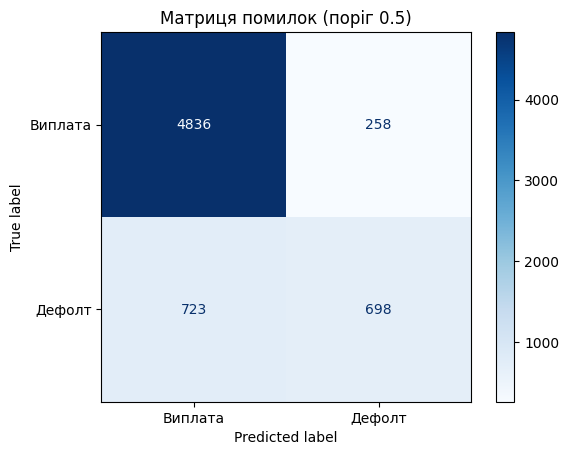

In [38]:
# 1.confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Виплата', 'Дефолт'])
disp.plot(cmap='Blues')
plt.title('Матриця помилок (поріг 0.5)')
plt.show()

При стандартному порозі 0.5, модель правильно визначила 4836 надійних клієнтів і 698 дефолтів.

Головна проблема: модель пропускає половину дефолтів (723 з 1421). Для банку(чи іншого кредитного бізнесу) це найдорожча помилка, тому стандартний поріг не оптимальний.

In [39]:
# 2.Метрики (accuracy, precision, recall, f1)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Метрики якості моделі:")
print('-'*30)
print(f"Accuracy (Точність):    {accuracy:.3f}")
print(f"Precision (Влучність):  {precision:.3f}")
print(f"Recall (Повнота):       {recall:.3f}")
print(f"F1-score:               {f1:.3f}")

Метрики якості моделі:
------------------------------
Accuracy (Точність):    0.849
Precision (Влучність):  0.730
Recall (Повнота):       0.491
F1-score:               0.587


Accuracy 84,9% виглядає дуже добре, проте ми навчали модель на незбалансованих даних, а значить ця метрика скоріше за все завищена.

Тому, краще орієнтуватись на інші три метрики:

Precision 73% - серед передбачених дефолтів, модель правильно визначила 73% як дефолт

Recall 49.1% - серед справжніх дефолтів, модель правильно визначила лише 49% як дефолт

F1-score 58.7 - гармонійне середнє precision і recall. Воно високе лише тоді, коли обидві метрики високі, і не враховує правильно передбачений клас «виплата». Тому F1 краще за accuracy підходить для незбалансованих даних, але вважає обидва типи помилок однаково важливими

Для банку пропущений дефолт (FN) дорожчий, ніж відмова надійному клієнту (FP), тому при порозі 0.5 модель недостатньо обережна. Зниження порогу може підвищити recall ціною більшої кількості відмов.

In [40]:
# Побудуйте ROC-криву та обчисліть AUC
from sklearn.metrics import roc_curve, roc_auc_score

# Обчислюємо AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba[:, 1])
auc = roc_auc_score(y_test, y_pred_proba[:, 1])
auc.round(3)

np.float64(0.856)

In [41]:
# Візуалізація
fig = go.Figure()
fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines', name=f'ROC (AUC = {auc:.3f})'))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(dash='dash'),
                        name='Випадковий класифікатор'))
fig.update_layout(
    title='ROC-крива',
    xaxis_title='False Positive Rate',
    yaxis_title='True Positive Rate',
    height=500
)
fig.show()



In [42]:
# Проаналізуйте важливість ознак
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
    'abs_coefficient': np.abs(model.coef_[0])
}).sort_values('abs_coefficient', ascending=False)

feature_importance

,feature,coefficient,abs_coefficient
6,loan_percent_income,1.379307,1.379307
3,loan_grade,1.133836,1.133836
4,loan_amnt,-0.635875,0.635875
10,person_home_ownership_OWN,-0.440663,0.440663
16,loan_intent_VENTURE,-0.397607,0.397607
11,person_home_ownership_RENT,0.387441,0.387441
12,loan_intent_EDUCATION,-0.324225,0.324225
15,loan_intent_PERSONAL,-0.212951,0.212951
14,loan_intent_MEDICAL,-0.070121,0.070121
7,cb_person_default_on_file,-0.057234,0.057234


**Висновки про якість моделі та які ознаки найбільше впливають на прогноз**

AUC = 0.856 - модель досить хороша. Можемо її використовувати, проте потрібно обрати підходящий бізнесу порог рішення.

Найбільше впливають такі ознаки:
loan_percent_income, loan_grade та loan_amnt.
loan_amnt та loan_percent_income впливає в різні напрями


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



In [43]:
# Аналіз різних порогів
thresholds = [0.3, 0.36, 0.45, 0.55, 0.6]
metrics_by_threshold = []

for threshold in thresholds:
    y_pred_custom = (y_pred_proba[:, 1] >= threshold).astype(int)

    metrics_by_threshold.append({
        'threshold': threshold,
        'precision': precision_score(y_test, y_pred_custom),
        'recall': recall_score(y_test, y_pred_custom),
        'f1': f1_score(y_test, y_pred_custom)
    })

metrics_df = pd.DataFrame(metrics_by_threshold)
metrics_df


,threshold,precision,recall,f1
0,0.30,0.588842,0.683322,0.632573
1,0.36,0.636686,0.632653,0.634663
2,0.45,0.707052,0.550317,0.618916
3,0.55,0.769697,0.446868,0.565450
4,0.60,0.796897,0.397607,0.530516


In [44]:
# Візуалізація
fig = px.line(
    metrics_df.melt(id_vars='threshold'),
    x='threshold',
    y='value',
    color='variable',
    title='Метрики при різних порогах рішення',
    labels={'value': 'Значення метрики', 'threshold': 'Поріг'},
)
fig.show()

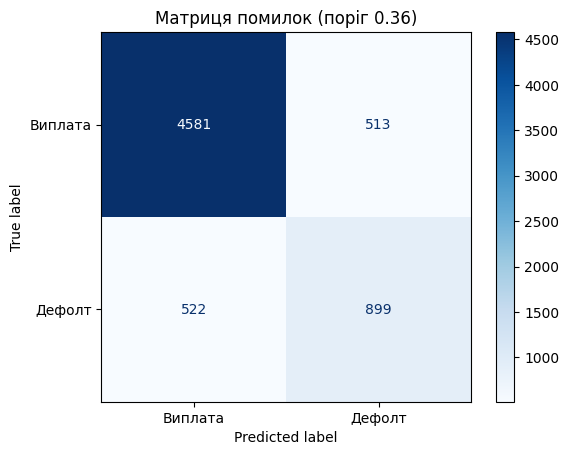

In [45]:
y_pred_opt = y_pred_proba[:,1]>=0.36
cm = confusion_matrix(y_test, y_pred_opt)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Виплата', 'Дефолт'])
disp.plot(cmap='Blues')
plt.title('Матриця помилок (поріг 0.36)')
plt.show()

In [46]:
accuracy = accuracy_score(y_test, y_pred_opt)
precision = precision_score(y_test, y_pred_opt)
recall = recall_score(y_test, y_pred_opt)
f1 = f1_score(y_test, y_pred_opt)

print("Метрики якості моделі:")
print('-'*30)
print(f"Accuracy (Точність):    {accuracy:.3f}")
print(f"Precision (Влучність):  {precision:.3f}")
print(f"Recall (Повнота):       {recall:.3f}")
print(f"F1-score:               {f1:.3f}")

Метрики якості моделі:
------------------------------
Accuracy (Точність):    0.841
Precision (Влучність):  0.637
Recall (Повнота):       0.633
F1-score:               0.635


Зниження порогу з 0.5 до 0.36 дозволило виявити на 201 дефолт більше (recall 49% → 63%) ціною 255 додаткових відмов надійним клієнтам (precision 73% → 64%). Accuracy при цьому майже не змінилась (84.9% → 84.1%), а F1 зріс (0.587 → 0.635).

Якщо припустити, що пропущений дефолт для банку приблизно в 5 разів дорожчий за відмову надійному клієнту, сумарні втрати при порозі 0.36 на ~19% нижчі, ніж при 0.5 (см.розрахунок внизу)

Тому для бізнес-задачі поріг 0.36 кращий за стандартний.

In [47]:
thr1 = 723 * 5 + 258
thr2 = 522 *  5 + 513
loss = (3873-3123)/3873*100
print(f'Втрати при порогу 0.5: {thr1} гр.од')
print(f'Втрати при порогу 0.36: {thr2} гр.од')
print(f'Різниця втрат: {loss:0.1f} %')

Втрати при порогу 0.5: 3873 гр.од
Втрати при порогу 0.36: 3123 гр.од
Різниця втрат: 19.4 %



---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

threshold = 0.36  # поріг, обраний у завданні 6

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=5),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}

results = []
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    proba = m.predict_proba(X_test_scaled)[:, 1]   # ймовірність дефолту
    pred = (proba >= threshold).astype(int)        # прогноз за обраним порогом

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba)
    })

In [49]:
results_df = pd.DataFrame(results).round(3)
print(results_df)

                 Model  Accuracy  Precision  Recall     F1    AUC
0  Logistic Regression     0.841      0.637   0.633  0.635  0.856
1        Decision Tree     0.911      0.924   0.647  0.761  0.884
2        Random Forest     0.926      0.898   0.747  0.816  0.931


Найбільші AUC, F1, Recall має модель  Random Forest. Найкращий Precision - у Decision Tree.

так як Recall для кредитного бізнесу важливіший за Precision через більшу вартість невизначення дефолтів, я би обрала модель Random Forest.